# Modelling: predicting the age of an abalone

# Imports

In [40]:
import itertools
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split

pd.set_option("display.max_columns", 500)

# Data

Same cleaning as in the EDA notebook.

In [41]:
DATA_PATH = "../data/abalone.csv"
TARGET = "Rings"
RANDOM_STATE = 42


def load_data(path: str) -> pd.DataFrame:
    """Load the abalone dataset."""
    return pd.read_csv(path)


def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Drop impossible values, then feature outliers beyond 3*IQR. The target is never filtered."""
    features = df.select_dtypes("number").columns.drop(TARGET)
    df = df[(df[features] > 0).all(axis=1)]

    q1 = df[features].quantile(0.25)
    q3 = df[features].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[features] < q1 - 3 * iqr) | (df[features] > q3 + 3 * iqr)).any(axis=1)
    return df[~outliers].reset_index(drop=True)


def build_features(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Encode Sex as infant vs adult and split the features from the target."""
    X = df.drop(columns=[TARGET, "Sex"]).assign(is_infant=(df["Sex"] == "I").astype(int))
    y = df[TARGET]
    return X, y

In [42]:
df = clean_data(load_data(DATA_PATH))
X, y = build_features(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Experiment tracking
Rings is an integer, so predictions are rounded to the nearest integer before computing every metric.

In [43]:
EXPERIMENT_NAME = "abalone-random-forest"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(EXPERIMENT_NAME)

CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# hyperparameters of each run of this session, by run id
run_params = {}


def rounded_mae(y_true: pd.Series, y_pred: np.ndarray) -> float:
    """MAE on predictions rounded to the nearest integer number of rings."""
    return mean_absolute_error(y_true, np.round(y_pred))


def rounded_rmse(y_true: pd.Series, y_pred: np.ndarray) -> float:
    """RMSE on predictions rounded to the nearest integer number of rings."""
    return root_mean_squared_error(y_true, np.round(y_pred))


SCORING = {
    "mae": make_scorer(rounded_mae, greater_is_better=False),
    "rmse": make_scorer(rounded_rmse, greater_is_better=False),
}


def train_and_log(params: dict, run_name: str) -> str:
    """Cross-validate a Random Forest with the given hyperparameters and log the run to MLflow."""
    model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params)
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING)
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(model.get_params())
        mlflow.log_metrics(
            {
                "cv_mae": -scores["test_mae"].mean(),
                "cv_rmse": -scores["test_rmse"].mean(),
            }
        )
    run_params[run.info.run_id] = params
    return run.info.run_id

# Baseline

Random Forest with the default hyperparameters (100 fully grown trees, all features considered at each split).

In [44]:
baseline_run_id = train_and_log({}, run_name="baseline")

# Hyperparameter tuning

In [45]:
param_grid = {
    "n_estimators": [300],
    "max_depth": [None, 8, 12],
    "min_samples_leaf": [1, 5, 10],
    "max_features": [1.0, 0.5, "sqrt"],
}

for values in itertools.product(*param_grid.values()):
    params = dict(zip(param_grid, values))
    run_name = "rf_" + "_".join(f"{name}={value}" for name, value in params.items())
    train_and_log(params, run_name=run_name)

# Comparison

In [46]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], order_by=["metrics.cv_mae ASC"])
runs = runs[runs["run_id"].isin(run_params)]

comparison = runs[
    [
        "run_id",
        "tags.mlflow.runName",
        "params.n_estimators",
        "params.max_depth",
        "params.min_samples_leaf",
        "params.max_features",
        "metrics.cv_mae",
        "metrics.cv_rmse",
    ]
].reset_index(drop=True)
comparison

,run_id,tags.mlflow.runName,params.n_estimators,params.max_depth,params.min_samples_leaf,params.max_features,metrics.cv_mae,metrics.cv_rmse
0,9f80f17b022b470c877592a23bd124f8,rf_n_estimators=300_max_depth=8_min_samples_le...,300,8,5,1.0,1.465225,2.156802
1,9198133099ca4b428c8bb26505d1d67a,rf_n_estimators=300_max_depth=8_min_samples_le...,300,8,10,1.0,1.467627,2.154334
2,afdc151d4ab94297b722e98e8a412d5b,rf_n_estimators=300_max_depth=None_min_samples...,300,None,10,1.0,1.476921,2.157415
3,1a13795068d9469180001897ecfbb4f4,rf_n_estimators=300_max_depth=12_min_samples_l...,300,12,10,1.0,1.477220,2.157782
4,b145cc27bcab4e4a8e711eb897dd9088,rf_n_estimators=300_max_depth=12_min_samples_l...,300,12,5,1.0,1.477221,2.169527
5,0027635e885f44d49c272e97ff61bf31,rf_n_estimators=300_max_depth=None_min_samples...,300,None,5,1.0,1.479621,2.168743
6,3bf4c3d627e3447ea9ae81ae371db4dc,rf_n_estimators=300_max_depth=8_min_samples_le...,300,8,5,0.5,1.483813,2.170615
7,55c59f47f4f84bf08b568ccf3ef8a595,rf_n_estimators=300_max_depth=8_min_samples_le...,300,8,1,0.5,1.485316,2.176973
8,6c3adea9fd554a58857934adbdf93d34,rf_n_estimators=300_max_depth=None_min_samples...,300,None,10,0.5,1.486214,2.163500
9,ef55af819a904b07b31aded23514015b,rf_n_estimators=300_max_depth=8_min_samples_le...,300,8,1,1.0,1.488308,2.185036


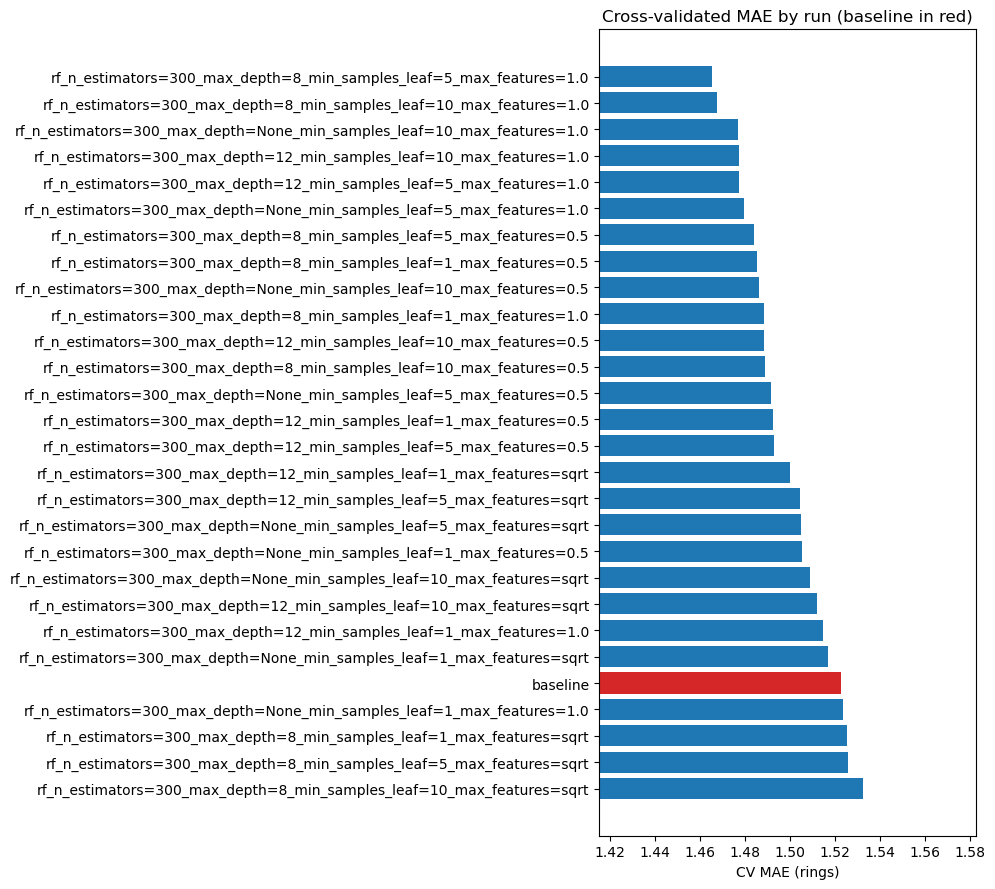

In [47]:
fig, ax = plt.subplots(figsize=(10, 9))
colors = ["tab:red" if name == "baseline" else "tab:blue" for name in comparison["tags.mlflow.runName"]]
ax.barh(comparison["tags.mlflow.runName"], comparison["metrics.cv_mae"], color=colors)
ax.invert_yaxis()
ax.set_xlim(comparison["metrics.cv_mae"].min() - 0.05, comparison["metrics.cv_mae"].max() + 0.05)
ax.set_xlabel("CV MAE (rings)")
ax.set_title("Cross-validated MAE by run (baseline in red)")
plt.tight_layout()
plt.show()

# Final evaluation on the test set

The baseline and the best configuration are refit on the whole training set and scored on the test set.

In [ ]:
def evaluate_on_test(run_id: str, log_model: bool = False) -> tuple[dict, RandomForestRegressor]:
    """Refit a run's configuration on the training set, score it on the test set and log the test metrics to the run."""
    model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **run_params[run_id])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    metrics = {
        "test_mae": rounded_mae(y_test, y_pred),
        "test_rmse": rounded_rmse(y_test, y_pred),
    }
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics(metrics)
        if log_model:
            mlflow.sklearn.log_model(
                model,
                name="model",
                input_example=X_train.head(),
                skops_trusted_types=["sklearn.tree._tree.Tree"],
            )
    return metrics, model


best_run_id = comparison.loc[0, "run_id"]
print(f"Best run: {comparison.loc[0, 'tags.mlflow.runName']}")

baseline_metrics, _ = evaluate_on_test(baseline_run_id)
best_metrics, best_model = evaluate_on_test(best_run_id, log_model=True)

mean_prediction = np.full(len(y_test), y_train.mean())
results = pd.DataFrame(
    {
        "mean predictor": {
            "test_mae": rounded_mae(y_test, mean_prediction),
            "test_rmse": rounded_rmse(y_test, mean_prediction),
        },
        "baseline": baseline_metrics,
        "best": best_metrics,
    }
).T
results

Best run: rf_n_estimators=300_max_depth=8_min_samples_leaf=5_max_features=1.0


/opt/anaconda3/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,test_mae,test_rmse
mean predictor,2.352518,3.253111
baseline,1.495204,2.175457
best,1.468825,2.137088


# Export the model

In [49]:
MODEL_PATH = Path("../models/model.pkl")
MODEL_PATH.parent.mkdir(exist_ok=True)

with open(MODEL_PATH, "wb") as f:
    pickle.dump(best_model, f)

print(f"Model saved to {MODEL_PATH.resolve()}")

Model saved to /Users/luccagazotto/Documents/HEC/MLOPS/xhec-mlops-2026-project/models/model.pkl
